# Ciblage humanitaire avec ML — version 4 : données MSNA (REACH), Nord-Kivu

La v3 portait sur un jeu simple (12 questions, 13,7 % d'éligibles). Cette version utilise `msna_household_targeting_dataset.csv`, plus proche d'une vraie évaluation multisectorielle (MSNA) :
**150 000 ménages, 36 colonnes, 9 modules** (démographie, déplacement, logement/HLP, abri, WASH, sécurité alimentaire, moyens de subsistance, protection, historique d'assistance).

**Ce qui rend ce jeu plus difficile**

| Difficulté | Section |
|---|---|
| La valeur texte `"None"` (« aucun ») est lue comme une valeur **manquante** par pandas : 318 586 faux manquants | 1 |
| Colonnes inutiles ou dangereuses : identifiant, date, constantes, une seconde cible dérivée | 2 |
| Incohérences internes (composition du ménage, historique d'assistance) | 2 |
| 30 variables candidates dont la majorité n'influence pas la décision des experts | 5 |
| Classes presque équilibrées (46,5 %) : les recettes de la v3 (F2) ne s'appliquent plus telles quelles | 6 |
| Bruit d'étiquette fort : la décision « experte » varie de ±10 points autour du seuil | 4 |

**Objectifs** : un modèle fiable, **le plus court possible à collecter** (moins de questions dans Kobo), explicable, avec un seuil justifié et équitable entre zones.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib, json
from pathlib import Path
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve
from sklearn.metrics import (roc_auc_score, average_precision_score, accuracy_score, recall_score, precision_score,
                             f1_score, fbeta_score, brier_score_loss, log_loss, confusion_matrix, ConfusionMatrixDisplay)
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier

plt.rcParams["figure.dpi"] = 110
SEED = 42
DATA = "msna_household_targeting_dataset.csv"
TARGET = "eligible_for_assistance"

## 1. Piège n°1 — les faux manquants

Par défaut, `pd.read_csv` convertit les chaînes `"None"`, `"NA"`, `"null"`… en `NaN`. Or dans ce questionnaire, `"None"` est une **réponse valide** :
aucun risque d'expulsion, aucun dommage au logement, aucune stratégie de survie, aucun risque de protection…

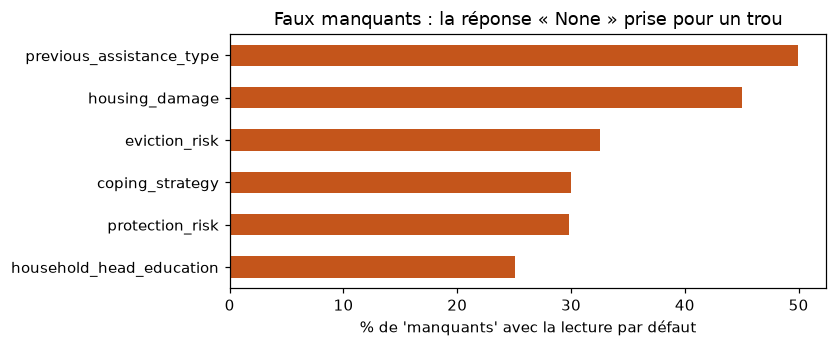

Lecture par défaut : 318,586 valeurs manquantes -> dropna() garderait 10,182 ménages sur 150,000 (6.8%)
Lecture correcte   : 0 valeur manquante

Exemple — eviction_risk : {'None': 48861, 'Medium': 30386, 'Low': 30236, 'High': 25272, 'Very High': 15245}


In [2]:
naif = pd.read_csv(DATA)
df = pd.read_csv(DATA, keep_default_na=False, na_values=[""])  # seule une cellule vide est un manquant

manq = naif.isna().mean().loc[lambda s: s > 0].sort_values()
ax = (manq * 100).plot.barh(color="#c4551b", figsize=(7, 3))
ax.set_xlabel("% de 'manquants' avec la lecture par défaut"); ax.set_title("Faux manquants : la réponse « None » prise pour un trou")
plt.show()

print(f"Lecture par défaut : {naif.isna().sum().sum():,} valeurs manquantes -> dropna() garderait {len(naif.dropna()):,} ménages sur {len(naif):,} ({len(naif.dropna())/len(naif):.1%})")
print(f"Lecture correcte   : {df.isna().sum().sum()} valeur manquante")
print("\nExemple — eviction_risk :", df.eviction_risk.value_counts().to_dict())

**Conséquences si on ne le voit pas**
- `dropna()` jette **93 % des ménages** et ne garde que ceux qui ont un risque, un dommage, une stratégie de survie… : un échantillon complètement biaisé.
- Une imputation par le mode remplacerait « aucun risque d'expulsion » par « risque moyen ». Ici, cette erreur est *par chance* sans effet, car les experts notent « None » et « Medium » de la même façon (0 point). Sur de vraies données, elle mélangerait deux situations différentes.
- Dans Kobo, ces questions devront avoir un **choix explicite « Aucun »**, et non une réponse laissée vide.

## 2. Audit des colonnes

In [3]:
y = df[TARGET].to_numpy()
audit = pd.DataFrame({
    "type": df.dtypes.astype(str),
    "modalites": df.nunique(),
    "exemple": df.iloc[0],
})
audit.loc[["household_id", "assessment_date", "province", "territory", "recommended_assistance", TARGET]]

,type,modalites,exemple
household_id,str,150000,HH_000001
assessment_date,str,365,2025-04-30
province,str,1,North Kivu
territory,str,1,Rutshuru
recommended_assistance,str,12,Food Assistance + Protection Assistance
eligible_for_assistance,int64,2,0


| Colonne | Décision | Raison |
|---|---|---|
| `household_id` | exclue | identifiant unique, aucun signal (sinon le modèle « apprend par cœur ») |
| `assessment_date` | exclue des variables | utilisée seulement pour une validation temporelle (section 8) |
| `province`, `territory` | exclues | constantes (une seule valeur) |
| `recommended_assistance` | **exclue** | seconde cible, calculée *après* l'évaluation : elle n'existe pas au moment de la décision (fuite) |
| `displacement_duration_months` | gardée mais redondante | vaut 0 sauf pour les PDI : entièrement déterminée par `household_status` |

In [4]:
incoherences = {
    "enfants <18 + personnes âgées > taille du ménage": ((df.children_under_18 + df.elderly_members) > df.household_size).mean(),
    "pas d'assistance reçue mais un type d'assistance précédent": ((df.received_assistance_last_6_months == "No") & (df.previous_assistance_type != "None")).mean(),
    "assistance reçue mais type 'None'": ((df.received_assistance_last_6_months == "Yes") & (df.previous_assistance_type == "None")).mean(),
    "PDI avec durée de déplacement nulle": ((df.household_status.str.startswith("Internally")) & (df.displacement_duration_months == 0)).mean(),
}
pd.Series(incoherences, name="part des ménages").map("{:.1%}".format).to_frame()

,part des ménages
enfants <18 + personnes âgées > taille du ménage,11.7%
pas d'assistance reçue mais un type d'assistance précédent,32.6%
assistance reçue mais type 'None',17.5%
PDI avec durée de déplacement nulle,0.0%


Ces incohérences viennent de la simulation : les colonnes ont été générées indépendamment les unes des autres. Sur le terrain, elles se préviennent **dans le formulaire Kobo** avec des contraintes, par exemple `. <= ${household_size}` sur le nombre d'enfants, ou `relevant` pour ne demander le type d'assistance que si le ménage en a reçu une.
Nous gardons les données telles quelles, mais ces colonnes sont à manier avec prudence.

## 3. La cible

Éligibles : 46.5% — classes presque équilibrées (contre 13,7 % en v3)


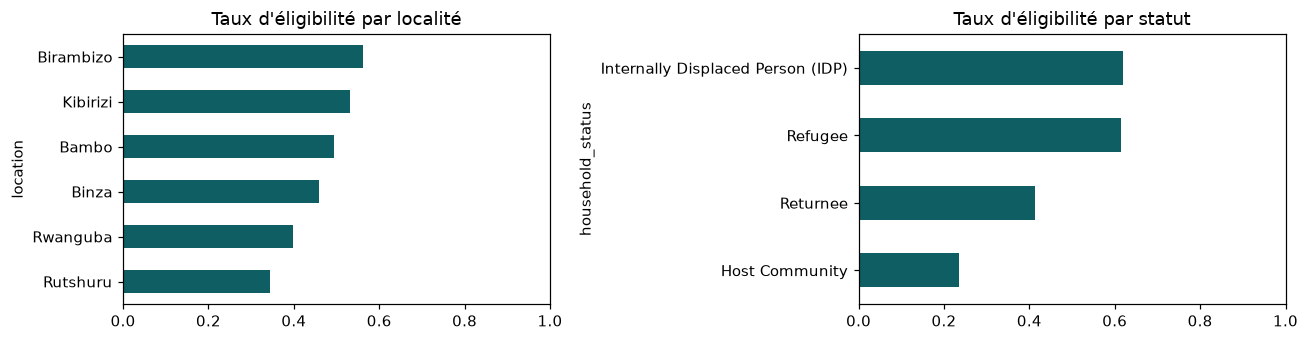

In [5]:
print(f"Éligibles : {y.mean():.1%} — classes presque équilibrées (contre 13,7 % en v3)")
fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
df.groupby("location")[TARGET].mean().sort_values().plot.barh(ax=axes[0], color="#0f5e63")
axes[0].set_title("Taux d'éligibilité par localité"); axes[0].set_xlim(0, 1)
df.groupby("household_status")[TARGET].mean().sort_values().plot.barh(ax=axes[1], color="#0f5e63")
axes[1].set_title("Taux d'éligibilité par statut"); axes[1].set_xlim(0, 1)
plt.tight_layout(); plt.show()

L'éligibilité varie fortement d'une localité à l'autre (34 % à Rutshuru, 56 % à Birambizo). Pourtant, la localité **n'entre pas** dans la grille des experts.
L'écart vient du fait que les zones à risque comptent plus de déplacés et de risques d'expulsion. Un bon modèle doit cibler les **conditions** du ménage, pas son **adresse** (section 9).

## 4. Le plafond de performance

Le notebook de génération révèle la règle : un score expert (déplacement +20, risque d'expulsion élevé +20, 1 repas/jour +20, etc.) auquel s'ajoute une **variation humaine aléatoire de −10 à +9 points**. Le ménage est éligible si le total atteint 45.
Un « oracle » qui connaîtrait exactement la grille aurait donc `P(éligible) = (score − 35) / 20`, borné entre 0 et 1. Aucun modèle ne peut faire mieux que lui.

In [6]:
def score_expert(d):
    s = np.zeros(len(d))
    s += np.select([d.household_status.isin(["Internally Displaced Person (IDP)", "Refugee"]), d.household_status.eq("Returnee")], [20, 10], 0)
    s += 20 * d.eviction_risk.isin(["High", "Very High"])
    s += 15 * d.housing_damage.isin(["Major", "Destroyed"])
    s += 15 * d.shelter_condition.eq("Unsafe")
    s += 10 * d.shelter_type.eq("Emergency Shelter")
    s += 20 * d.meals_per_day.eq(1)
    s += 15 * d.food_consumption_score.eq("Poor")
    s += 15 * d.protection_risk.isin(["High", "Very High"])
    s += 10 * d.disability_member.eq("Yes")
    s += 5 * d.pregnant_or_lactating_woman.eq("Yes")
    s += 5 * d.household_head_gender.eq("Female")
    return s

p_oracle = np.clip((score_expert(df) - 35) / 20, 0, 1)
print(f"Oracle : ROC-AUC {roc_auc_score(y, p_oracle):.4f} | accuracy max ≈ {accuracy_score(y, p_oracle >= 0.5):.1%} | "
      f"{((p_oracle > 0) & (p_oracle < 1)).mean():.0%} des ménages ont une issue incertaine même pour l'oracle")

Oracle : ROC-AUC 0.9815 | accuracy max ≈ 91.6% | 26% des ménages ont une issue incertaine même pour l'oracle


Environ **8 % d'erreurs sont irréductibles**. Un modèle autour de 91–92 % d'accuracy a donc déjà atteint le plafond. Chercher plus, avec des modèles plus lourds ou plus de réglages, ce serait apprendre le bruit (sur-apprentissage).
*Bien sûr, cette grille cachée n'est connue que parce que les données sont simulées. Elle sert de référence, jamais de variable d'entrée.*

## 5. Préparation, découpage et comparaison des modèles

In [7]:
EXCLUES = ["household_id", "assessment_date", "province", "territory", "recommended_assistance", TARGET]
NUMERIQUES = ["household_size", "children_under_5", "children_under_18", "elderly_members", "household_head_age",
              "displacement_duration_months", "distance_to_water_minutes"]
X = df.drop(columns=EXCLUES)
X["meals_per_day"] = X["meals_per_day"].astype(str)  # 1 / 2 / 3 : un seuil métier (1 repas), traité en catégorie
TOUTES = list(X.columns)
print(f"{len(TOUTES)} variables candidates")

X_tr, X_tmp, y_tr, y_tmp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEED)
X_va, X_te, y_va, y_te = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)
p_or_va, p_or_te = p_oracle[X_va.index], p_oracle[X_te.index]
print(f"train {len(X_tr):,} / validation {len(X_va):,} / test {len(X_te):,}")

def pipeline(cols, clf, scale=False, drop=None):
    cat = [c for c in cols if c not in NUMERIQUES]
    num = [c for c in cols if c in NUMERIQUES]
    pre = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False, drop=drop), cat),
                             ("num", StandardScaler() if scale else "passthrough", num)])
    steps = [("pre", pre)] + ([("scale", StandardScaler())] if scale else []) + [("clf", clf)]
    return Pipeline(steps)

def evaluer(nom, p, yv, seuil=0.5):
    pred = (p >= seuil).astype(int)
    return {"modèle": nom, "ROC-AUC": roc_auc_score(yv, p), "PR-AUC": average_precision_score(yv, p),
            "log-loss": log_loss(yv, np.clip(p, 1e-6, 1 - 1e-6)), "Brier": brier_score_loss(yv, p),
            "accuracy": accuracy_score(yv, pred), "rappel": recall_score(yv, pred), "précision": precision_score(yv, pred)}

30 variables candidates
train 105,000 / validation 22,500 / test 22,500


In [8]:
modeles = {
    "Régression logistique": pipeline(TOUTES, LogisticRegression(max_iter=5000), scale=True),
    "LightGBM": pipeline(TOUTES, LGBMClassifier(n_estimators=500, learning_rate=0.03, num_leaves=31, random_state=SEED, verbose=-1)),
    "XGBoost": pipeline(TOUTES, XGBClassifier(n_estimators=400, max_depth=4, learning_rate=0.05, random_state=SEED)),
}
lignes, probas_va = [evaluer("Oracle (référence)", p_or_va, y_va)], {}
for nom, pipe in modeles.items():
    pipe.fit(X_tr, y_tr)
    probas_va[nom] = pipe.predict_proba(X_va)[:, 1]
    lignes.append(evaluer(nom + " — 30 variables", probas_va[nom], y_va))
pd.DataFrame(lignes).set_index("modèle").style.format("{:.4f}").highlight_max(subset=["ROC-AUC", "accuracy"], color="#e0f1e6")

,ROC-AUC,PR-AUC,log-loss,Brier,accuracy,rappel,précision
modèle,,,,,,,
Oracle (référence),0.9804,0.9702,0.1596,0.0551,0.9128,0.9418,0.8793
Régression logistique — 30 variables,0.9806,0.9790,0.1734,0.0573,0.9127,0.9013,0.9100
LightGBM — 30 variables,0.9804,0.9788,0.1780,0.0567,0.9127,0.9087,0.9040
XGBoost — 30 variables,0.9802,0.9786,0.1936,0.0587,0.9108,0.8894,0.9164


Les trois modèles sont **à égalité avec l'oracle**. Le boosting n'apporte rien sur la régression logistique, ce qui est logique : la décision des experts est une somme de points, c'est-à-dire une relation linéaire.
Le vrai levier n'est donc pas le choix de l'algorithme. Il se trouve dans **le nombre de questions nécessaires** et dans **le choix du seuil**.

## 6. Sélection des variables : combien de questions faut-il vraiment poser ?

L'**importance par permutation** consiste à mélanger une colonne de la validation et à mesurer la perte de ROC-AUC. Une question dont le mélange ne change rien ne sert pas à la décision.
Elle se calcule sur la **validation**, sans aucune connaissance de la grille cachée.

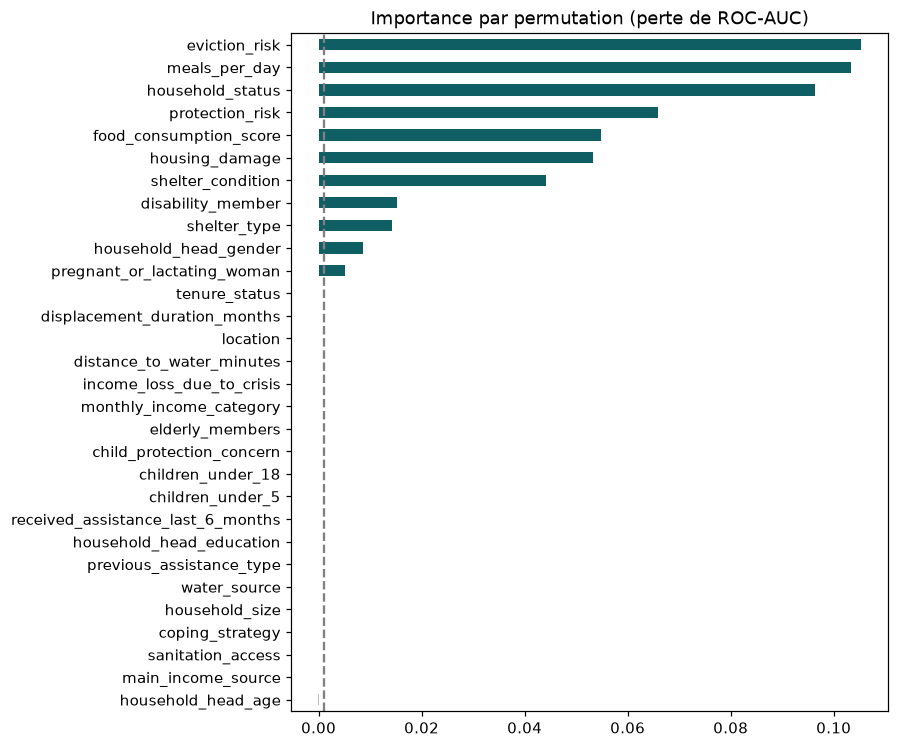

In [9]:
perm = permutation_importance(modeles["LightGBM"], X_va, y_va, scoring="roc_auc", n_repeats=5, random_state=SEED, n_jobs=-1)
imp = pd.Series(perm.importances_mean, index=TOUTES).sort_values(ascending=False)
ax = imp.iloc[::-1].plot.barh(figsize=(7, 8), color=["#0f5e63" if v > 0.001 else "#bbb" for v in imp.iloc[::-1]])
ax.axvline(0.001, ls="--", c="grey"); ax.set_title("Importance par permutation (perte de ROC-AUC)"); plt.show()

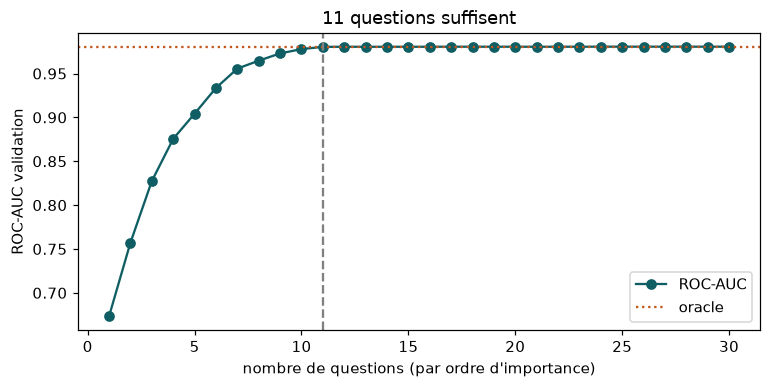

Questions retenues (11) : ['eviction_risk', 'meals_per_day', 'household_status', 'protection_risk', 'food_consumption_score', 'housing_damage', 'shelter_condition', 'disability_member', 'shelter_type', 'household_head_gender', 'pregnant_or_lactating_woman']

Questions écartées : ['location', 'household_size', 'children_under_5', 'children_under_18', 'elderly_members', 'household_head_age', 'household_head_education', 'displacement_duration_months', 'tenure_status', 'water_source', 'distance_to_water_minutes', 'sanitation_access', 'coping_strategy', 'main_income_source', 'income_loss_due_to_crisis', 'monthly_income_category', 'child_protection_concern', 'received_assistance_last_6_months', 'previous_assistance_type']


In [10]:
courbe = []
for k in range(1, len(imp) + 1):
    cols = list(imp.index[:k])
    p = pipeline(cols, LogisticRegression(max_iter=5000), scale=True).fit(X_tr[cols], y_tr).predict_proba(X_va[cols])[:, 1]
    courbe.append({"k": k, "ROC-AUC": roc_auc_score(y_va, p), "ajout": cols[-1]})
courbe = pd.DataFrame(courbe).set_index("k")
K = int(courbe.index[courbe["ROC-AUC"] >= courbe["ROC-AUC"].max() - 0.0005][0])  # plus petit k à 0,0005 du maximum
SELECTION = list(imp.index[:K])

ax = courbe["ROC-AUC"].plot(marker="o", figsize=(8, 3.5), color="#0f5e63")
ax.axhline(roc_auc_score(y_va, p_or_va), ls=":", c="#c4551b", label="oracle"); ax.axvline(K, ls="--", c="grey")
ax.set_xlabel("nombre de questions (par ordre d'importance)"); ax.set_ylabel("ROC-AUC validation"); ax.legend()
ax.set_title(f"{K} questions suffisent"); plt.show()
print(f"Questions retenues ({K}) :", SELECTION)
print("\nQuestions écartées :", [c for c in TOUTES if c not in SELECTION])

**Résultat clé.** La procédure retrouve, sans la connaître, exactement les variables de la grille des experts. Les autres (distance à l'eau, revenus, éducation, taille du ménage, localité…) n'apportent rien à la décision d'**éligibilité**.

**Conséquence pour le terrain** : le module d'éligibilité du formulaire Kobo peut passer d'une trentaine de questions à une dizaine. Les entretiens sont plus courts, il y a moins de fatigue et donc moins d'erreurs de saisie, et moins de données personnelles sont collectées (principe de minimisation).
Les autres questions restent utiles pour d'autres analyses de la MSNA (type d'assistance, planification), mais pas pour cette décision.

In [11]:
modele = pipeline(SELECTION, LogisticRegression(max_iter=5000), scale=True).fit(X_tr[SELECTION], y_tr)
p_va = modele.predict_proba(X_va[SELECTION])[:, 1]
p_te = modele.predict_proba(X_te[SELECTION])[:, 1]
pd.DataFrame([evaluer("Oracle", p_or_va, y_va), evaluer("Régression logistique — 30 variables", probas_va["Régression logistique"], y_va),
              evaluer(f"Régression logistique — {K} variables", p_va, y_va)]).set_index("modèle").style.format("{:.4f}")

,ROC-AUC,PR-AUC,log-loss,Brier,accuracy,rappel,précision
modèle,,,,,,,
Oracle,0.9804,0.9702,0.1596,0.0551,0.9128,0.9418,0.8793
Régression logistique — 30 variables,0.9806,0.9790,0.1734,0.0573,0.9127,0.9013,0.9100
Régression logistique — 11 variables,0.9804,0.9788,0.1735,0.0574,0.9120,0.8980,0.9114


## 7. Choisir le seuil : un arbitrage explicite entre deux erreurs

En v3, le F2 fonctionnait parce que les éligibles étaient rares. Ici (46,5 % d'éligibles), maximiser le F2 pousse le seuil vers 0,05–0,10 : on inclurait presque **60 % des ménages**, ce qu'aucun budget ne permet.

La bonne approche consiste à **expliciter le coût relatif** des deux erreurs, puis à en déduire le seuil :
- erreur d'**exclusion** (un ménage éligible rejeté) : coût `c_ex` ;
- erreur d'**inclusion** (un ménage non éligible retenu) : coût `c_in`.

Si les probabilités sont **calibrées**, le seuil qui minimise le coût total est `c_in / (c_in + c_ex)`. Il faut donc d'abord vérifier la calibration.

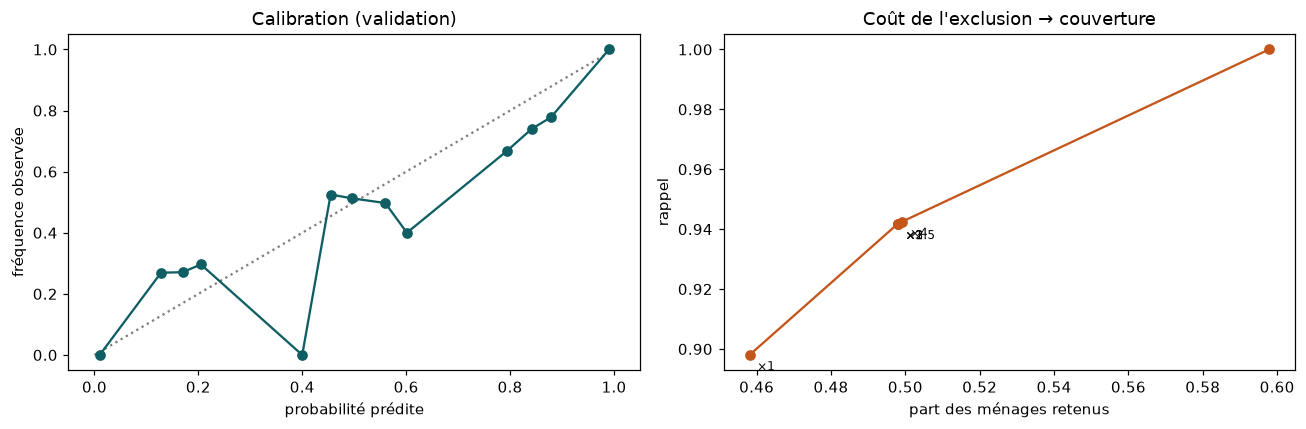

,exclusion coûte ×,seuil,ménages retenus,rappel,précision,éligibles exclus,inclusions à tort
exclusion ×1,1.000000,0.500,45.8%,89.8%,91.1%,1067,913
exclusion ×1.5,1.500000,0.400,49.8%,94.2%,87.9%,609,1352
exclusion ×2,2.000000,0.333,49.8%,94.2%,87.9%,609,1353
exclusion ×3,3.000000,0.250,49.8%,94.2%,87.9%,609,1353
exclusion ×4,4.000000,0.200,49.9%,94.3%,87.8%,601,1372
F2 maximal (recette v3),nan,0.050,59.8%,100.0%,77.8%,0,2990


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
frac, moy = calibration_curve(y_va, p_va, n_bins=15)
axes[0].plot([0, 1], [0, 1], ls=":", c="grey"); axes[0].plot(moy, frac, marker="o", c="#0f5e63")
axes[0].set_xlabel("probabilité prédite"); axes[0].set_ylabel("fréquence observée"); axes[0].set_title("Calibration (validation)")

ratios = [1, 1.5, 2, 3, 4]
tab = []
for r in ratios:
    s = 1 / (1 + r)
    pred = p_va >= s
    tab.append({"exclusion coûte ×": r, "seuil": round(s, 3), "ménages retenus": pred.mean(), "rappel": recall_score(y_va, pred),
                "précision": precision_score(y_va, pred), "éligibles exclus": int(((~pred) & (y_va == 1)).sum()),
                "inclusions à tort": int((pred & (y_va == 0)).sum())})
grille_s = np.round(np.arange(0.05, 0.96, 0.01), 2)
s_f2 = grille_s[int(np.argmax([fbeta_score(y_va, p_va >= t, beta=2) for t in grille_s]))]
pred = p_va >= s_f2
tab.append({"exclusion coûte ×": np.nan, "seuil": s_f2, "ménages retenus": pred.mean(), "rappel": recall_score(y_va, pred),
            "précision": precision_score(y_va, pred), "éligibles exclus": int(((~pred) & (y_va == 1)).sum()),
            "inclusions à tort": int((pred & (y_va == 0)).sum())})
tab = pd.DataFrame(tab)
tab.index = [f"exclusion ×{r:g}" for r in ratios] + ["F2 maximal (recette v3)"]
axes[1].plot(tab["ménages retenus"], tab["rappel"], marker="o", c="#c4551b")
for _, r in tab.iloc[:-1].iterrows():
    axes[1].annotate(f"×{r['exclusion coûte ×']:g}", (r["ménages retenus"], r["rappel"]), textcoords="offset points", xytext=(5, -10), fontsize=8)
axes[1].set_xlabel("part des ménages retenus"); axes[1].set_ylabel("rappel"); axes[1].set_title("Coût de l'exclusion → couverture")
plt.tight_layout(); plt.show()
tab.style.format({"seuil": "{:.3f}", "ménages retenus": "{:.1%}", "rappel": "{:.1%}", "précision": "{:.1%}"})

Le modèle est bien calibré : les points suivent la diagonale. Le seuil peut donc se lire directement comme une décision de politique de ciblage.

**Lecture du tableau**
- **F2 maximal (recette de la v3)** : le rappel est quasi parfait, mais près de 60 % des ménages sont retenus. Avec 46,5 % d'éligibles, cette métrique ne freine plus les inclusions.
- **Exclusion ×2, soit un seuil de 1/3 (choix retenu)** : le rappel passe d'environ 90 % à environ 94 %, et le nombre d'éligibles exclus baisse d'environ 40 %. En contrepartie, on retient environ 4 points de ménages en plus.
- **Effet de palier** : tous les ratios entre 1,5 et 4 donnent la *même* décision. Le score des experts avance par paliers de 5 points, donc les probabilités se regroupent sur quelques niveaux (≈ 0, 0,25, 0,5, 0,75, 1). La décision est ainsi **robuste** au choix exact du ratio, ce qui la rend plus facile à défendre.

Le ratio de coût reste un **paramètre de programme, pas un paramètre technique**. Il doit être validé avec l'équipe (budget, gravité de la crise), et ce tableau permet d'en discuter concrètement.

,ROC-AUC,PR-AUC,log-loss,Brier,accuracy,rappel,précision
modèle,,,,,,,
"Oracle, seuil 0,5",0.9819,0.9721,0.1546,0.0529,0.9177,0.9448,0.8857
"Modèle 11 variables, seuil 0,5",0.9819,0.9804,0.1664,0.0546,0.9169,0.9055,0.9149
"Modèle 11 variables, seuil 0.33",0.9819,0.9804,0.1664,0.0546,0.9177,0.9448,0.8857


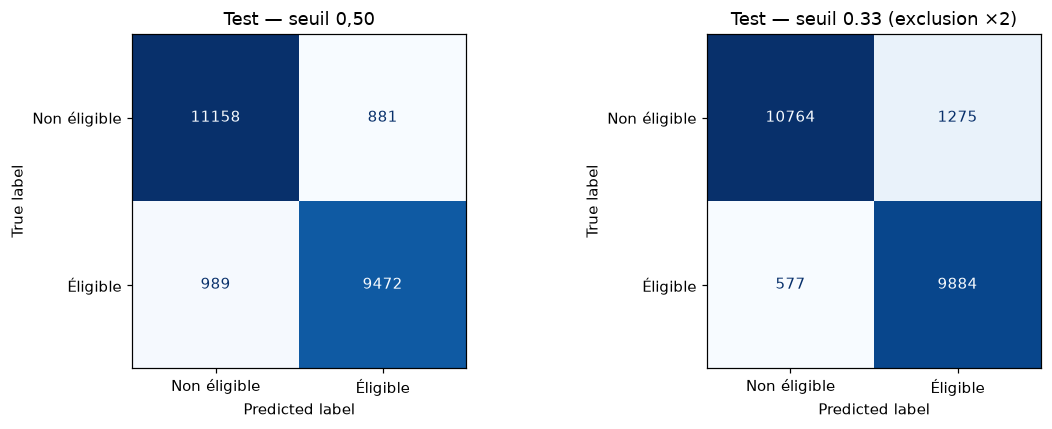

In [13]:
RATIO = 2
SEUIL = 1 / (1 + RATIO)
res = pd.DataFrame([evaluer("Oracle, seuil 0,5", p_or_te, y_te), evaluer(f"Modèle {K} variables, seuil 0,5", p_te, y_te),
                    evaluer(f"Modèle {K} variables, seuil {SEUIL:.2f}", p_te, y_te, SEUIL)]).set_index("modèle")
display(res.style.format("{:.4f}"))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (titre, s) in zip(axes, [("seuil 0,50", 0.5), (f"seuil {SEUIL:.2f} (exclusion ×{RATIO})", SEUIL)]):
    ConfusionMatrixDisplay(confusion_matrix(y_te, p_te >= s), display_labels=["Non éligible", "Éligible"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"Test — {titre}")
plt.tight_layout(); plt.show()

## 8. Robustesse

- **Validation croisée stratifiée (5 plis)** : la performance est-elle stable ?
- **Validation temporelle** : entraîner sur janvier–septembre et tester sur octobre–décembre, comme en exploitation réelle, où le modèle sert sur des évaluations *futures*.

In [14]:
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
sc = cross_val_score(pipeline(SELECTION, LogisticRegression(max_iter=5000), scale=True), X[SELECTION], y, cv=cv, scoring="roc_auc", n_jobs=-1)
print(f"Validation croisée : ROC-AUC = {sc.mean():.4f} ± {sc.std():.4f}")

dates = pd.to_datetime(df.assessment_date)
avant, apres = dates < "2025-10-01", dates >= "2025-10-01"
m_t = pipeline(SELECTION, LogisticRegression(max_iter=5000), scale=True).fit(X.loc[avant, SELECTION], y[avant])
p_t = m_t.predict_proba(X.loc[apres, SELECTION])[:, 1]
print(f"Validation temporelle (train jan–sep : {avant.sum():,} ménages, test oct–déc : {apres.sum():,}) : "
      f"ROC-AUC {roc_auc_score(y[apres], p_t):.4f}, rappel {recall_score(y[apres], p_t >= SEUIL):.1%} au seuil {SEUIL:.2f}")

Validation croisée : ROC-AUC = 0.9815 ± 0.0003


Validation temporelle (train jan–sep : 112,126 ménages, test oct–déc : 37,874) : ROC-AUC 0.9817, rappel 94.6% au seuil 0.33


## 9. Équité : le modèle traite-t-il les zones et les groupes de la même façon ?

Pour chaque localité et pour le sexe du chef de ménage, on compare le **rappel** (part des éligibles effectivement retenus) et le **taux d'inclusion à tort**.
Un écart important signifierait que certains groupes sont systématiquement plus exclus que d'autres.

In [15]:
test = X_te.assign(y=y_te, pred=(p_te >= SEUIL).astype(int), location=df.loc[X_te.index, "location"])
def equite(col):
    g = test.groupby(col)
    return pd.DataFrame({
        "ménages": g.size(),
        "taux éligibles réel": g.y.mean(),
        "taux retenus": g.pred.mean(),
        "rappel": g.apply(lambda d: recall_score(d.y, d.pred)),
        "inclusions à tort / non éligibles": g.apply(lambda d: ((d.pred == 1) & (d.y == 0)).sum() / max((d.y == 0).sum(), 1)),
    })
fmt = {c: "{:.1%}" for c in ["taux éligibles réel", "taux retenus", "rappel", "inclusions à tort / non éligibles"]}
display(equite("location").style.format(fmt).background_gradient(subset=["rappel"], cmap="RdYlGn", vmin=0.9, vmax=1))
display(equite("household_head_gender").style.format(fmt))

,ménages,taux éligibles réel,taux retenus,rappel,inclusions à tort / non éligibles
location,,,,,
Bambo,3716,48.1%,50.7%,94.8%,9.8%
Binza,3712,46.4%,49.1%,94.2%,10.0%
Birambizo,3747,56.8%,60.0%,95.2%,13.8%
Kibirizi,3790,53.4%,56.9%,95.4%,12.7%
Rutshuru,3790,33.3%,36.9%,93.1%,8.8%
Rwanguba,3745,41.0%,44.0%,93.4%,9.7%


,ménages,taux éligibles réel,taux retenus,rappel,inclusions à tort / non éligibles
household_head_gender,,,,,
Female,7950,53.0%,56.1%,94.8%,12.3%
Male,14550,42.9%,46.1%,94.3%,9.8%


Le rappel est homogène entre les localités (environ 93 à 95 %). La localité n'est pas une variable du modèle : les écarts de taux d'éligibilité s'expliquent par les conditions réelles des ménages, et non par une « pénalité géographique ». Les inclusions à tort sont un peu plus fréquentes dans les zones les plus touchées (Birambizo, Kibirizi), là où davantage de ménages sont proches du seuil.
Le sexe du chef de ménage, lui, **est** un critère de la grille des experts (+5 points pour une femme cheffe de ménage). Le modèle le reproduit, et c'est un choix de politique de ciblage, assumé et visible (section 10).

## 10. Explicabilité : le modèle retrouve la grille des experts

On ré-estime la régression logistique **sans standardisation** et avec, pour chaque question, la réponse la moins vulnérable comme référence. Chaque coefficient se lit alors comme « ce que cette réponse ajoute, par rapport à la situation de référence ».
On convertit ensuite ces coefficients en **points**, en prenant « 1 repas par jour = 20 points », pour les comparer à la grille réelle (cachée) des experts.

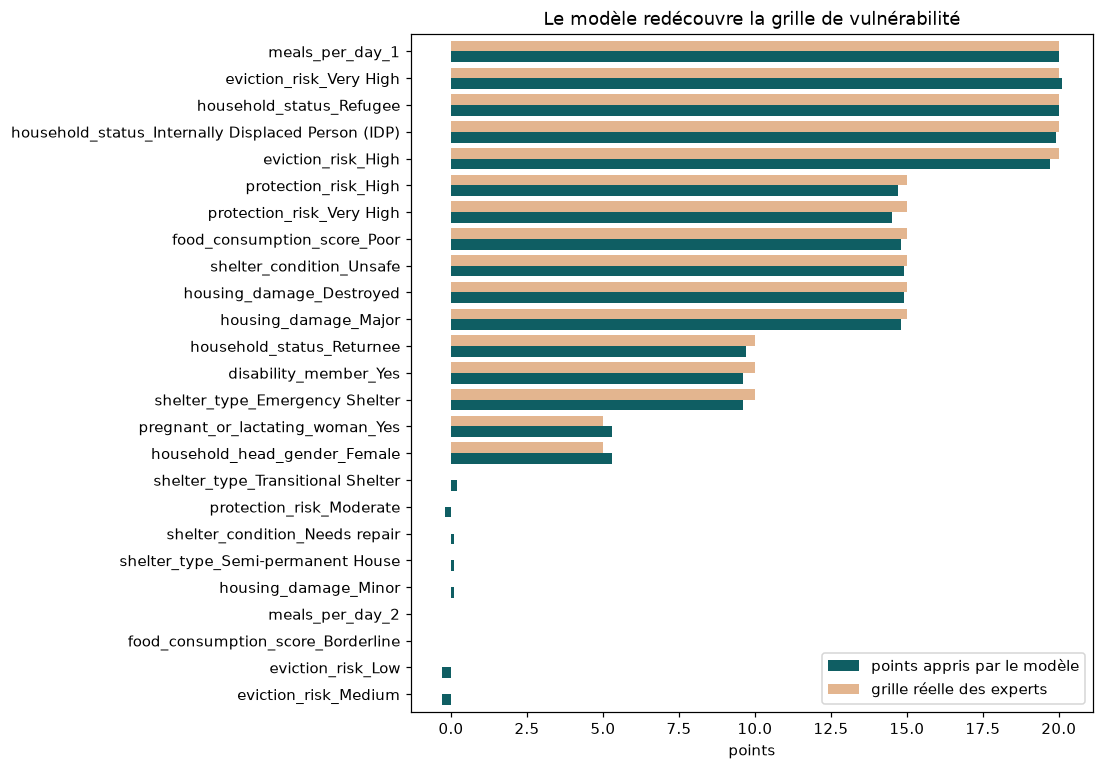

Écart moyen absolu : 0.2 point


In [16]:
REFERENCES = {
    "household_status": "Host Community", "eviction_risk": "None", "housing_damage": "None", "shelter_condition": "Good",
    "shelter_type": "Permanent House", "meals_per_day": "3", "food_consumption_score": "Acceptable", "protection_risk": "None",
    "disability_member": "No", "pregnant_or_lactating_woman": "No", "household_head_gender": "Male",
}
cat_sel = [c for c in SELECTION if c not in NUMERIQUES]
lisible = pipeline(SELECTION, LogisticRegression(max_iter=5000, C=10), drop=[REFERENCES.get(c, X_tr[c].mode()[0]) for c in cat_sel])
lisible.fit(X_tr[SELECTION], y_tr)
noms = lisible.named_steps["pre"].get_feature_names_out()
coef = pd.Series(lisible.named_steps["clf"].coef_[0], index=[n.split("__", 1)[1] for n in noms])
points = coef / coef["meals_per_day_1"] * 20

GRILLE = {"household_status_Internally Displaced Person (IDP)": 20, "household_status_Refugee": 20, "household_status_Returnee": 10,
          "eviction_risk_High": 20, "eviction_risk_Very High": 20, "eviction_risk_Low": 0, "eviction_risk_Medium": 0,
          "housing_damage_Major": 15, "housing_damage_Destroyed": 15, "housing_damage_Minor": 0,
          "shelter_condition_Unsafe": 15, "shelter_condition_Needs repair": 0,
          "shelter_type_Emergency Shelter": 10, "shelter_type_Transitional Shelter": 0, "shelter_type_Semi-permanent House": 0,
          "meals_per_day_1": 20, "meals_per_day_2": 0, "food_consumption_score_Poor": 15, "food_consumption_score_Borderline": 0,
          "protection_risk_High": 15, "protection_risk_Very High": 15, "protection_risk_Moderate": 0,
          "disability_member_Yes": 10, "pregnant_or_lactating_woman_Yes": 5, "household_head_gender_Female": 5}
cmp_ = pd.DataFrame({"points appris par le modèle": points.round(1), "grille réelle des experts": pd.Series(GRILLE)}).dropna()
cmp_ = cmp_.sort_values("grille réelle des experts")
ax = cmp_.plot.barh(figsize=(8, 8), color=["#0f5e63", "#e3b58f"], width=0.8)
ax.set_title("Le modèle redécouvre la grille de vulnérabilité"); ax.set_xlabel("points"); plt.show()
print(f"Écart moyen absolu : {(cmp_.iloc[:, 0] - cmp_.iloc[:, 1]).abs().mean():.1f} point")

Le modèle n'a jamais vu la grille, et pourtant il retrouve chaque poids à environ un point près. Les réponses non notées par les experts (Low, Medium, Minor, Borderline…) restent proches de 0.
C'est la meilleure preuve que le modèle est **interprétable et fidèle** : chaque décision peut s'expliquer en « points » à un·e superviseur·e, comme dans le dashboard de la v3.

## 11. Sauvegarde du modèle

In [17]:
sortie = Path("modele_v4"); sortie.mkdir(exist_ok=True)
joblib.dump({"pipeline": modele, "variables": SELECTION, "seuil": SEUIL}, sortie / "model_v4.joblib")
meta = {
    "jeu_de_donnees": DATA, "modele": "regression_logistique", "variables": SELECTION, "seuil": SEUIL, "ratio_cout_exclusion_inclusion": RATIO,
    "test": {k: round(float(v), 4) for k, v in evaluer("v4", p_te, y_te, SEUIL).items() if k != "modèle"},
    "lecture_csv": "pd.read_csv(..., keep_default_na=False, na_values=['']) — 'None' est une réponse valide",
}
(sortie / "metadata.json").write_text(json.dumps(meta, ensure_ascii=False, indent=2), encoding="utf-8")
meta

{'jeu_de_donnees': 'msna_household_targeting_dataset.csv',
 'modele': 'regression_logistique',
 'variables': ['eviction_risk',
  'meals_per_day',
  'household_status',
  'protection_risk',
  'food_consumption_score',
  'housing_damage',
  'shelter_condition',
  'disability_member',
  'shelter_type',
  'household_head_gender',
  'pregnant_or_lactating_woman'],
 'seuil': 0.3333333333333333,
 'ratio_cout_exclusion_inclusion': 2,
 'test': {'ROC-AUC': 0.9819,
  'PR-AUC': 0.9804,
  'log-loss': 0.1664,
  'Brier': 0.0546,
  'accuracy': 0.9177,
  'rappel': 0.9448,
  'précision': 0.8857},
 'lecture_csv': "pd.read_csv(..., keep_default_na=False, na_values=['']) — 'None' est une réponse valide"}

## Conclusion

| | v3 (jeu simple) | v4 (MSNA) |
|---|---|---|
| Difficulté principale | déséquilibre (13,7 %) | faux manquants, variables inutiles, bruit d'étiquette fort |
| Questions utilisées par le modèle | 12 | **11** sur 30 candidates |
| Seuil | maximise le F2 | coût explicite exclusion / inclusion (×2) sur des probabilités calibrées : seuil 1/3, rappel ≈ 94 % |
| Modèle | régression logistique pondérée | régression logistique (le boosting n'apporte rien) |
| Plafond atteint | oui | oui (ROC-AUC égale à celle de l'oracle) |

**Enseignements**
1. **La lecture des données compte autant que le modèle** : un `read_csv` par défaut transforme « aucun risque » en « donnée manquante ».
2. **Moins de questions, même performance.** La sélection par importance par permutation ramène le module d'éligibilité de 30 à 11 questions, exactement celles de la grille des experts.
3. Avec des classes équilibrées, le seuil doit venir d'une **décision explicite de programme** (coût relatif des erreurs), pas d'une métrique par défaut.
4. Au-delà de 91–92 % d'accuracy, les erreurs restantes sont du **désaccord humain** (le bruit de ±10 points) : c'est là que la revue humaine du dashboard apporte de la valeur.

**Pour déployer la v4** dans l'API `eligibilite_api` : mettre à jour `app/schema.py` avec les questions retenues (choix « Aucun » explicites), régénérer le formulaire Kobo, puis ré-entraîner avec `training/train.py`.